In [1]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import image as mpimg

# sklearn modules
import sklearn

# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

df_locs.head()

,County,Station_Name,Observation_ID,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,57.075424,-2.335825
2,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,57.055146,-3.083181
3,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,57.050129,-2.603567
4,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,56.988040,-3.486198


In [2]:
# Load data  

# Merge into one useful dataframe 
id_cols = ['County', 'Station_Name', 'Observation_ID']
date_cols = [c for c in df_avg.columns if c not in id_cols]

def melt_river_data(df, value_name):
    """ Converts wide format (dates as columns) to long format (dates as rows)"""
    melted = df.melt(
        id_vars=id_cols, 
        value_vars=date_cols, 
        var_name='Date', 
        value_name=value_name
    )
    return melted

df_avg_long = melt_river_data(df_avg, 'Avg_Level')
df_min_long = melt_river_data(df_min, 'Min_Level')
df_max_long = melt_river_data(df_max, 'Max_Level')

# Merge long format df_min and long format df_avg
df_combined = pd.merge(
    df_avg_long, 
    df_min_long, 
    on=id_cols + ['Date'],  
    how='outer'             
)

# Then merge result with long format df_max 
df_combined = pd.merge(
    df_combined, 
    df_max_long, 
    on=id_cols + ['Date'], 
    how='outer'
)

# Finally merge with df_locs
df_combined = pd.merge(
    df_combined,
    df_locs,
    on=id_cols,
)

df_combined.head()

,County,Station_Name,Observation_ID,Date,Avg_Level,Min_Level,Max_Level,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2015,NaN,NaN,NaN,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2016,NaN,NaN,NaN,57.424758,-2.802015
2,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2017,NaN,NaN,NaN,57.424758,-2.802015
3,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2018,0.431,0.391,0.475,57.424758,-2.802015
4,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,01/01/2019,0.221,0.217,0.226,57.424758,-2.802015


avg is missing 525,877 values (30.61%)
min is missing 525,877 values (30.61%)
max is missing 525,877 values (30.61%)


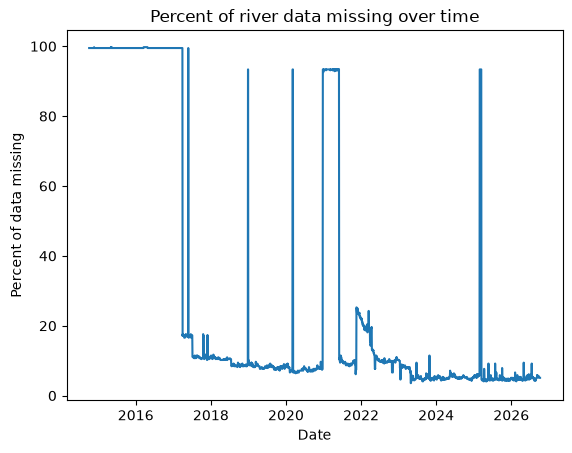

In [3]:
for name, df in [("avg", df_avg), ("min", df_min), ("max", df_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

plt.plot(pd.to_datetime(missing.index, dayfirst=True), missing)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()


df_combined['Date'] = pd.to_datetime(df_combined['Date'], format='%d/%m/%Y')




In [5]:
#===============
# DF AVERAGE
#================
#Work withdata in wide form
df_avg = df_avg.replace(999999.999, np.nan) # get rid of likely imputed 999999 values
dates1 = pd.to_datetime(df_avg.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals1 = df_avg.iloc[:, 3:].copy()
vals1.columns = dates1
vals1.index = df_avg["Observation_ID"]        # or Station_Name, if it's unique
vals1 = vals1.T                                # rows = dates, columns = stations


# full daily data with NA rows where gaps were 
vals1 = vals1.reindex(pd.date_range(vals1.index.min(), vals1.index.max(), freq="D")) 

# drop stations not in scotland based on location plots
vals1 = vals1.drop(columns = ['argyll-and-bute__portrush-argyll-and-bute-tidal-level__obs2', 'wigtown__bangor-wigtown-tidal-level__obs2', 'wigtown__port-erin-wigtown__obs2'])

# drop big station-wide outage DAYS
good1 = vals1[vals1.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop STATIONS that are missing too much of what's left
miss1 = good1.isna().mean()
keep1 = miss1.index[miss1 <= 0.1]       # only keep stations with 90% of data retained 
filtered_avg = good1[keep1]





In [7]:
#=================
# DF MIN
#==================
#Work withdata in wide form
df_min = df_min.replace(999999.999, np.nan) # get rid of likely imputed 999999 values
dates2 = pd.to_datetime(df_min.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals2 = df_min.iloc[:, 3:].copy()
vals2.columns = dates2
vals2.index = df_min["Observation_ID"]        # or Station_Name, if it's unique
vals2 = vals2.T                                # rows = dates, columns = stations

# full daily data with NA rows where gaps were 
vals2 = vals2.reindex(pd.date_range(vals2.index.min(), vals2.index.max(), freq="D")) 

# drop stations not in scotland based on location plots
vals2 = vals2.drop(columns = ['argyll-and-bute__portrush-argyll-and-bute-tidal-level__obs2', 'wigtown__bangor-wigtown-tidal-level__obs2', 'wigtown__port-erin-wigtown__obs2'])

# drop big station-wide outage DAYS
good2 = vals2[vals2.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop STATIONS that are missing too much of what's left
miss2 = good2.isna().mean()
keep2 = miss2.index[miss2 <= 0.1]       # only keep stations with 90% of data retained 
filtered_min = good2[keep2]
filtered_min


Observation_ID,aberdeenshire__bogie-redcraig__obs1,aberdeenshire__dee-grampian-mar-lodge__obs1,aberdeenshire__dee-grampian-park__obs1,aberdeenshire__dee-grampian-polhollick__obs1,aberdeenshire__dee-grampian-woodend__obs1,aberdeenshire__deveron-avochie__obs1,aberdeenshire__deveron-huntly-gs__obs1,aberdeenshire__don-alford__obs1,aberdeenshire__don-culfork__obs1,aberdeenshire__don-haughton__obs1,...,wigtown__blackwater-of-dee-loch-dee-outlet__obs1,wigtown__bladnoch-low-malzie__obs1,wigtown__cree-newton-stewart__obs1,wigtown__cree-wheeb-bridge__obs1,wigtown__piltanton-burn-barsolus__obs1,wigtown__port-erin-wigtown-tidal-level__obs1,wigtown__portpatrick-wigtown-tidal-level__obs2,wigtown__portpatrick-wigtown__obs1,wigtown__water-of-luce-airyhemming__obs1,wigtown__water-of-minnoch-minnoch-bridge__obs1
2017-03-31,0.219,0.972,1.016,0.624,0.700,0.278,0.524,0.740,0.061,2.363,...,1.245,1.532,1.820,0.839,0.614,NaN,NaN,NaN,0.902,1.232
2017-04-01,0.216,0.823,1.084,0.606,0.783,0.281,0.520,0.738,0.062,2.361,...,1.050,1.033,0.992,0.609,0.539,NaN,NaN,NaN,0.598,0.767
2017-04-02,0.214,0.767,1.042,0.560,0.722,0.280,0.518,0.743,0.068,2.373,...,0.883,0.863,0.786,0.522,0.510,NaN,NaN,NaN,0.518,0.660
2017-04-03,0.209,0.733,0.958,0.516,0.654,0.274,0.515,0.729,0.057,2.355,...,0.785,0.800,0.707,0.486,0.500,NaN,NaN,NaN,0.492,0.624
2017-04-04,0.204,0.731,0.926,0.508,0.629,0.262,0.514,0.723,0.052,2.342,...,0.818,0.780,0.816,0.475,0.486,NaN,NaN,NaN,0.489,0.701
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-04,0.130,0.740,0.940,0.500,0.600,0.220,0.460,0.640,0.140,2.200,...,0.700,0.810,0.820,0.520,0.550,-1.32,1.10,-0.70,0.460,0.670
2026-10-05,0.120,0.710,0.910,0.480,0.570,0.220,0.450,0.620,0.130,2.180,...,0.640,0.760,0.760,0.490,0.520,-1.29,1.09,-0.71,0.430,0.650
2026-10-06,0.120,0.680,0.870,0.450,0.530,0.210,0.440,0.620,0.130,2.170,...,0.580,0.730,0.700,0.460,0.520,-1.56,0.90,-0.91,0.420,0.620
2026-10-07,0.120,0.670,0.840,0.430,0.500,0.210,0.430,0.610,0.130,2.160,...,0.530,0.700,0.650,0.450,0.520,0.40,2.72,0.92,0.410,0.600


In [8]:
#=================
# DF MAX
#==================
#Work withdata in wide form
df_max = df_max.replace(999999.999, np.nan) # get rid of likely imputed 999999 values
dates3 = pd.to_datetime(df_max.columns[3:], dayfirst=True)   # dd/mm/yyyy strings
vals3 = df_min.iloc[:, 3:].copy()
vals3.columns = dates3
vals3.index = df_max["Observation_ID"]        # or Station_Name, if it's unique
vals3 = vals3.T                                # rows = dates, columns = stations

# full daily data with NA rows where gaps were 
vals3 = vals3.reindex(pd.date_range(vals3.index.min(), vals3.index.max(), freq="D")) 

# drop stations not in scotland based on location plots
vals3 = vals3.drop(columns = ['argyll-and-bute__portrush-argyll-and-bute-tidal-level__obs2', 'wigtown__bangor-wigtown-tidal-level__obs2', 'wigtown__port-erin-wigtown__obs2'])

# drop big station-wide outage DAYS
good3 = vals3[vals3.isna().mean(axis=1) <= 0.5] # compute for each date fraction of stations missing,get rid of dates with more than 50% missing

# drop STATIONS that are missing too much of what's left
miss3 = good3.isna().mean()
keep3 = miss3.index[miss3 <= 0.1]       # only keep stations with 90% of data retained 
filtered_max = good3[keep3]

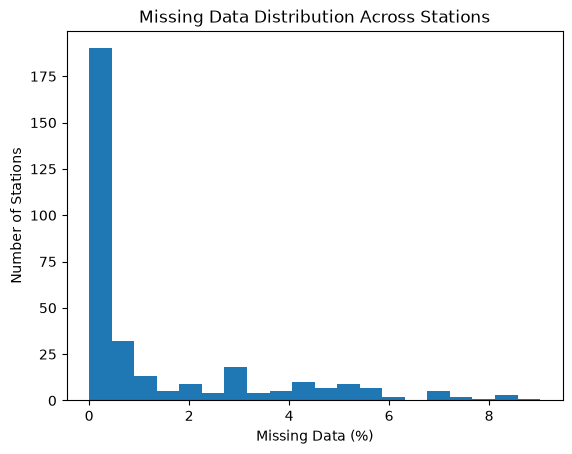

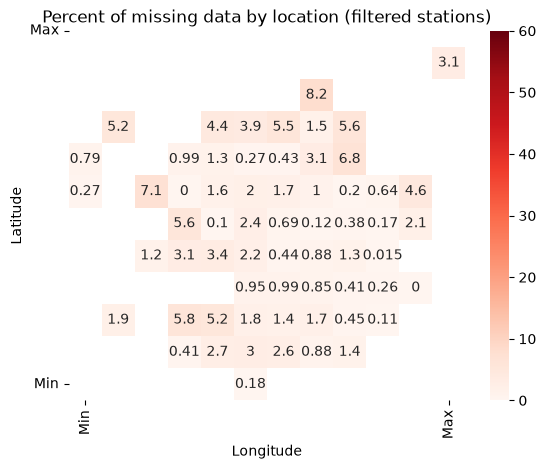

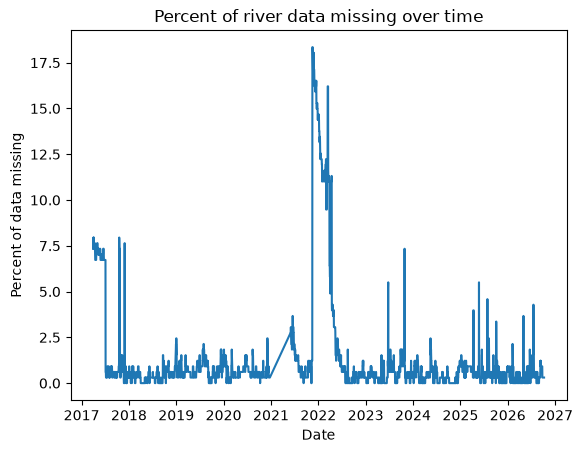

In [19]:
#histogram 
miss_fil = filtered_avg.isna().mean() * 100 # calculate updated percentage missing per station
plt.hist(miss_fil, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

#heatmap
df_map = df_locs.copy()
df_map.index = df_avg["Observation_ID"]          
df_map["Missing"] = miss_fil          

df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered=True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing", index="Latitude",
                                  columns="Longitude", observed=False)
sns.heatmap(heatmap_data, annot=True, cmap="Reds", vmin=0, vmax=60)
plt.title("Percent of missing data by location (filtered stations)")
plt.xticks([0.5, 11.5], ["Min", "Max"])
plt.yticks([0.5, 11.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

#plot timeseries of percentage missing for all stations
miss_fil_row = filtered_avg.isnull().mean(axis=1) * 100
filtered_avg['miss_fil_row'] = filtered_avg.isnull().mean(axis=1) * 100
filtered_avg

column_index = list(filtered_avg.columns).index('miss_fil_row')

missing_plot = filtered_avg.iloc[:,column_index]

plt.plot(pd.to_datetime(missing_plot.index, dayfirst=True), missing_plot)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()